# Challenge 2: Music Genre Classification (Kaggle `shai-music-genre-classification`)
**Nhóm 5 – Lớp DCT124C1 – Trường Đại học Sài Gòn** | GVHD: TS. Đỗ Như Tài  
Thành viên: Phạm Minh Khôi (3124411135), Trương Thuận Phú (3124411234), Nguyễn Mạnh Thắng (3124411283), Nguyễn Hoàng Quân (3124411250)

Notebook chạy **một lượt từ đầu đến cuối** và sinh ra toàn bộ số liệu, hình (`figs/`), bảng (`outputs/`) và `submission.csv` dùng trong paper, slide, poster.

Đặc điểm của quy trình:
1. Mọi bước học từ dữ liệu (imputation, chuẩn hóa, mã hóa Artist theo nhãn) nằm **trong `Pipeline`** nên mỗi fold chỉ học từ tập train của fold đó.
2. Mã hóa theo nhãn (target encoding) của `Artist Name` dùng thống kê **out-of-fold bên trong** tập train để không rò rỉ nhãn của chính mẫu đó.
3. Có **ablation** cho từng nhóm đặc trưng và cho xử lý mất cân bằng lớp.
4. Báo cáo cả **Accuracy** và **Macro-F1** vì trang cuộc thi không công bố rõ thước đo trong bản nhóm đọc được.

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

warnings.filterwarnings('ignore')
SEED = 42
for d in ('figs', 'outputs'): os.makedirs(d, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11})
NAVY, BLUE, ORANGE, GREEN, GREY = '#1F3A5F', '#4C78A8', '#F58518', '#54A24B', '#8C8C8C'
RES = {}
kf = StratifiedKFold(5, shuffle=True, random_state=SEED)
print('Môi trường sẵn sàng.')

Môi trường sẵn sàng.


## 1. Dữ liệu

In [2]:
train = pd.read_csv('data/train.csv'); test = pd.read_csv('data/test.csv'); sample = pd.read_csv('data/sample_submission.csv')
print('Train:', train.shape, '| Test:', test.shape, '| Sample submission:', sample.shape, list(sample.columns))
NUM = ['Popularity','danceability','energy','key','loudness','mode','speechiness','acousticness','instrumentalness','liveness','valence','tempo','duration_in min/ms','time_signature']
n_cls = train.Class.nunique(); y = train.Class.values
cc = train.Class.value_counts().sort_index(); print('Phân bố lớp:', cc.to_dict()); print('Tỉ lệ lớp lớn nhất (baseline đoán đa số): %.3f' % (cc.max() / len(train)))
miss_tr = train[NUM].isna().mean(); miss_te = test[NUM].isna().mean()
print('Thiếu (train %):', (miss_tr[miss_tr > 0] * 100).round(1).to_dict()); print('Thiếu (test %):', (miss_te[miss_te > 0] * 100).round(1).to_dict())
seen = test['Artist Name'].isin(train['Artist Name']).mean(); print('Tỉ lệ mẫu test có nghệ sĩ đã thấy trong train: %.3f' % seen)
RES.update(n_train=len(train), n_test=len(test), n_cls=int(n_cls), class_counts={int(k): int(v) for k, v in cc.items()}, majority_share=round(float(cc.max() / len(train)), 4),
           miss_train={k: round(v * 100, 1) for k, v in miss_tr[miss_tr > 0].items()}, miss_test={k: round(v * 100, 1) for k, v in miss_te[miss_te > 0].items()},
           artists_train=int(train['Artist Name'].nunique()), artist_seen_share=round(float(seen), 3), dup_rows=int(train.drop(columns='Id').duplicated().sum()))

Train: (14396, 18) | Test: (3600, 17) | Sample submission: (3600, 2) ['Id', 'Class']
Phân bố lớp: {0: 500, 1: 1098, 2: 1018, 3: 322, 4: 310, 5: 1157, 6: 2069, 7: 461, 8: 1483, 9: 2019, 10: 3959}
Tỉ lệ lớp lớn nhất (baseline đoán đa số): 0.275
Thiếu (train %): {'Popularity': 2.3, 'key': 11.2, 'instrumentalness': 24.6}
Thiếu (test %): {'Popularity': 2.6, 'key': 11.2, 'instrumentalness': 23.2}
Tỉ lệ mẫu test có nghệ sĩ đã thấy trong train: 0.638


## 2. Khám phá dữ liệu

Số mẫu có duration < 100 (đơn vị phút) trong train: 2075 (14.4%); trong test: 505 (14.0%)
Tỉ lệ duration-theo-phút theo lớp: {0: 1.0, 1: 0.0, 2: 0.0, 3: 1.0, 4: 1.0, 5: 0.0, 6: 0.0, 7: 1.0, 8: 0.0, 9: 0.17, 10: 0.04}
Độ thuần nhãn trung bình của nghệ sĩ có ≥ 5 bài: 0.73


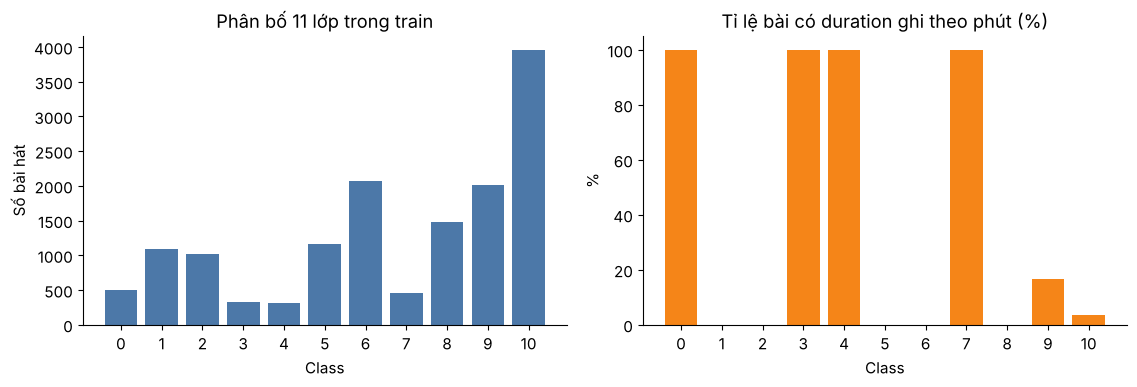

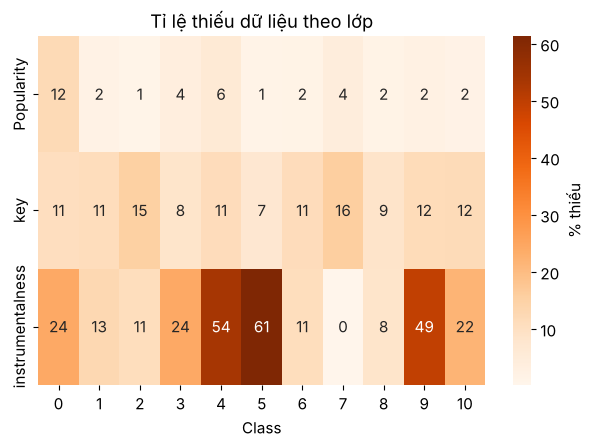

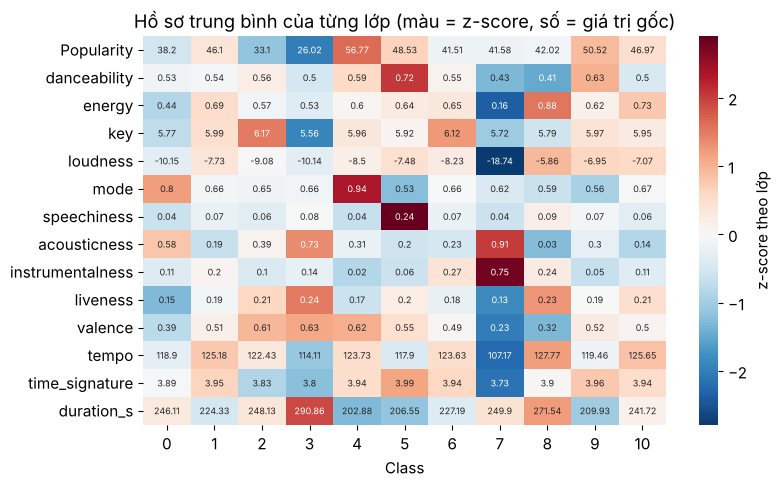

In [3]:
d = train['duration_in min/ms']; is_min = d < 100
share_min = train.assign(m=is_min).groupby('Class').m.mean()
print('Số mẫu có duration < 100 (đơn vị phút) trong train: %d (%.1f%%); trong test: %d (%.1f%%)' % (is_min.sum(), is_min.mean() * 100, (test['duration_in min/ms'] < 100).sum(), (test['duration_in min/ms'] < 100).mean() * 100))
print('Tỉ lệ duration-theo-phút theo lớp:', share_min.round(2).to_dict())
RES.update(minutes_train=round(float(is_min.mean() * 100), 1), minutes_test=round(float((test['duration_in min/ms'] < 100).mean() * 100), 1), minutes_by_class={int(k): round(float(v), 2) for k, v in share_min.items()})
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].bar(cc.index, cc.values, color=BLUE); ax[0].set_title('Phân bố 11 lớp trong train'); ax[0].set_xlabel('Class'); ax[0].set_ylabel('Số bài hát'); ax[0].set_xticks(cc.index)
ax[1].bar(share_min.index, share_min.values * 100, color=ORANGE); ax[1].set_title('Tỉ lệ bài có duration ghi theo phút (%)'); ax[1].set_xlabel('Class'); ax[1].set_ylabel('%'); ax[1].set_xticks(cc.index)
plt.tight_layout(); plt.savefig('figs/fig2_class_distribution.png', dpi=200); plt.show()

mm = train.assign(**{c: train[c].isna() for c in ['Popularity', 'key', 'instrumentalness']}).groupby('Class')[['Popularity', 'key', 'instrumentalness']].mean() * 100
RES['missing_by_class'] = {c: {int(k): round(float(v), 1) for k, v in mm[c].items()} for c in mm}
fig, ax = plt.subplots(figsize=(6.2, 4.6)); sns.heatmap(mm.T, annot=True, fmt='.0f', cmap='Oranges', cbar_kws={'label': '% thiếu'}, ax=ax); ax.set_xlabel('Class'); ax.set_ylabel('')
ax.set_title('Tỉ lệ thiếu dữ liệu theo lớp')
plt.tight_layout(); plt.savefig('figs/fig3_missing_by_class.png', dpi=200); plt.show()

feat_cols = [c for c in NUM if c != 'duration_in min/ms'] + ['duration_s']
tmp = train.copy(); tmp['duration_s'] = np.where(is_min, d * 60, d / 1000)
prof = tmp.groupby('Class')[feat_cols].mean(); z = (prof - prof.mean()) / prof.std()
fig, ax = plt.subplots(figsize=(8.2, 5)); sns.heatmap(z.T, cmap='RdBu_r', center=0, annot=prof.T.round(2), fmt='', annot_kws={'size': 6.5}, cbar_kws={'label': 'z-score theo lớp'}, ax=ax)
ax.set_title('Hồ sơ trung bình của từng lớp (màu = z-score, số = giá trị gốc)'); ax.set_xlabel('Class')
plt.tight_layout(); plt.savefig('figs/fig4_class_profile.png', dpi=200); plt.show()
g = train.groupby('Artist Name').Class.agg(['count', lambda s: s.value_counts(normalize=True).iloc[0]]); g.columns = ['n', 'purity']
RES['artist_purity_mean_n5'] = round(float(g[g.n >= 5].purity.mean()), 2); print('Độ thuần nhãn trung bình của nghệ sĩ có ≥ 5 bài:', RES['artist_purity_mean_n5'])

## 3. Đặc trưng
- **A – Thô (14 biến số):** 14 đặc trưng âm thanh/số của bài hát (thiếu → median trong Pipeline).
- **B – A + đặc trưng kỹ thuật:** cờ đơn vị `dur_is_minutes`, `dur_ms` (quy về ms), 3 cờ thiếu dữ liệu.
- **C – B + nghệ sĩ:** tần suất xuất hiện của nghệ sĩ (đếm trên train + test, không dùng nhãn) và mã hóa theo nhãn của `Artist Name` (11 biến, smoothed, out-of-fold trong Pipeline).

In [4]:
class ArtistTE(BaseEstimator, TransformerMixin):
    """Target encoding có làm mượt (m) cho Artist Name; hàng train dùng thống kê out-of-fold bên trong để không tự rò rỉ nhãn."""
    def __init__(self, m=5.0, n_splits=5, seed=42): self.m = m; self.n_splits = n_splits; self.seed = seed
    def _stats(self, a, yy): df = pd.DataFrame(np.eye(self.K_)[yy]); df['a'] = a; return df.groupby('a').sum()
    def _enc(self, a, g):
        out = np.tile(self.prior_, (len(a), 1)).astype(float); idx = pd.Index(g.index).get_indexer(a); ok = idx >= 0
        G = g.values[idx[ok]]; out[ok] = (G + self.m * self.prior_) / (G.sum(1, keepdims=True) + self.m); return out
    def fit(self, X, yy):
        yy = np.asarray(yy); self.K_ = int(yy.max()) + 1; self.prior_ = np.bincount(yy, minlength=self.K_) / len(yy)
        self.g_ = self._stats(X['artist'].values, yy); return self
    def fit_transform(self, X, yy):
        self.fit(X, yy); yy = np.asarray(yy); a = X['artist'].values; out = np.zeros((len(X), self.K_))
        for tri, vai in StratifiedKFold(self.n_splits, shuffle=True, random_state=self.seed).split(a, yy):
            out[vai] = self._enc(a[vai], self._stats(a[tri], yy[tri]))
        return self._merge(X, out)
    def transform(self, X): return self._merge(X, self._enc(X['artist'].values, self.g_))
    def _merge(self, X, enc):
        Z = X.drop(columns=['artist']).copy()
        for k in range(self.K_): Z[f'artist_te_{k}'] = enc[:, k]
        return Z

freq = pd.concat([train['Artist Name'], test['Artist Name']]).value_counts()
def build(df, fs):
    X = df[NUM].copy(); X.columns = [c.replace('duration_in min/ms', 'duration_raw') for c in X.columns]
    if fs in ('B', 'C'):
        dd = df['duration_in min/ms']; X['dur_is_minutes'] = (dd < 100).astype(int); X['dur_ms'] = np.where(dd < 100, dd * 60000, dd)
        for c in ['Popularity', 'key', 'instrumentalness']: X[c + '_missing'] = df[c].isna().astype(int)
    if fs == 'C': X['artist_freq'] = df['Artist Name'].map(freq).values; X['artist'] = df['Artist Name'].values
    return X
XA, XB, XC = build(train, 'A'), build(train, 'B'), build(train, 'C'); XS = {'A: thô (14)': XA, 'B: + kỹ thuật': XB, 'C: + nghệ sĩ': XC}
print({k: v.shape[1] for k, v in XS.items()}, '(C chưa tính 11 biến mã hóa nghệ sĩ, được sinh trong Pipeline)')
def make_pipe(model, fs):
    steps = ([('te', ArtistTE())] if fs.startswith('C') else []) + [('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('model', model)]
    return Pipeline(steps)

{'A: thô (14)': 14, 'B: + kỹ thuật': 19, 'C: + nghệ sĩ': 21} (C chưa tính 11 biến mã hóa nghệ sĩ, được sinh trong Pipeline)


## 4. Thực nghiệm chính: 7 mô hình × 3 tập đặc trưng (5-fold CV phân tầng, không rò rỉ)

   FeatureSet               Model    Acc  Acc_Std     F1  F1_Std  CV_time_s
  A: thô (14) Logistic Regression 0.4966   0.0085 0.5108  0.0138     1.6389
  A: thô (14)          KNN (k=15) 0.4775   0.0078 0.5041  0.0048     1.9696
  A: thô (14)           SVM (RBF) 0.5223   0.0061 0.5351  0.0041    20.9662
  A: thô (14)       Random Forest 0.5134   0.0053 0.5593  0.0037    16.9129
  A: thô (14)         Extra Trees 0.5029   0.0085 0.5489  0.0069    10.7556
  A: thô (14)            HistGBDT 0.5383   0.0056 0.5727  0.0060     7.4155
  A: thô (14)                 MLP 0.5247   0.0062 0.5520  0.0061     9.7729
B: + kỹ thuật Logistic Regression 0.5072   0.0106 0.5273  0.0120     2.0686
B: + kỹ thuật          KNN (k=15) 0.4800   0.0053 0.5227  0.0077     0.4501
B: + kỹ thuật           SVM (RBF) 0.5297   0.0086 0.5520  0.0074    20.9799
B: + kỹ thuật       Random Forest 0.5125   0.0098 0.5597  0.0071    18.4232
B: + kỹ thuật         Extra Trees 0.5052   0.0100 0.5582  0.0068    10.7443
B: + kỹ thuậ

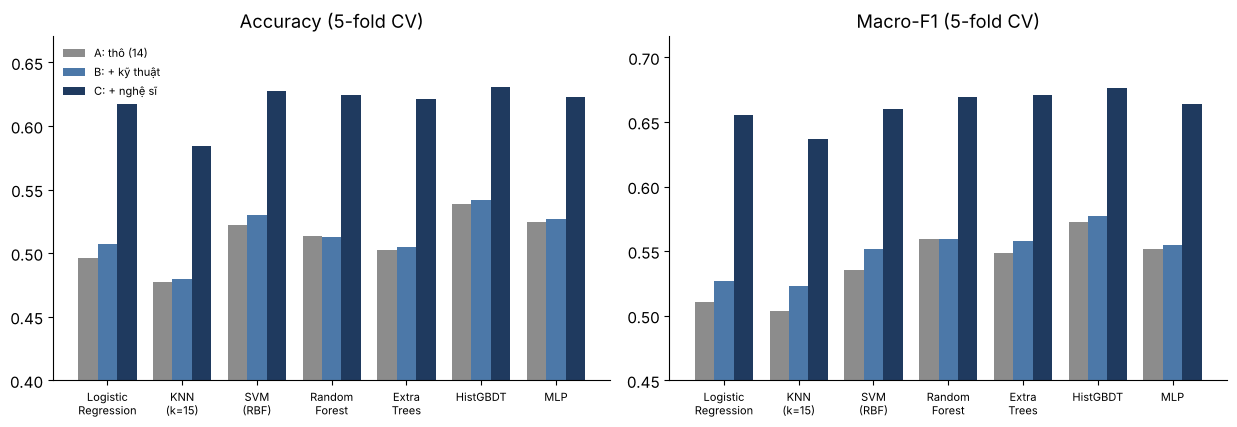

In [5]:
MODELS = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=2000),
    'KNN (k=15)': lambda: KNeighborsClassifier(15),
    'SVM (RBF)': lambda: SVC(),
    'Random Forest': lambda: RandomForestClassifier(300, n_jobs=-1, random_state=SEED),
    'Extra Trees': lambda: ExtraTreesClassifier(300, n_jobs=-1, random_state=SEED),
    'HistGBDT': lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=.08, random_state=SEED),
    'MLP': lambda: MLPClassifier((128, 64), max_iter=300, early_stopping=True, random_state=SEED),
}
rows = []
for fs, Xf in XS.items():
    for mn, mk in MODELS.items():
        t0 = time.time(); r = cross_validate(make_pipe(mk(), fs), Xf, y, cv=kf, scoring=('accuracy', 'f1_macro'))
        rows.append(dict(FeatureSet=fs, Model=mn, Acc=r['test_accuracy'].mean(), Acc_Std=r['test_accuracy'].std(), F1=r['test_f1_macro'].mean(), F1_Std=r['test_f1_macro'].std(), CV_time_s=time.time() - t0))
bench = pd.DataFrame(rows); bench.to_csv('outputs/benchmark_results.csv', index=False)
print(bench.round(4).to_string(index=False)); RES['bench'] = bench.round(4).to_dict('records')
b = bench.loc[bench.Acc.idxmax()]; print('\nTốt nhất theo Accuracy:', b.FeatureSet, b.Model, round(b.Acc, 4), '| Macro-F1', round(b.F1, 4))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=False); w = .26
for a, met, tt in zip(ax, ('Acc', 'F1'), ('Accuracy', 'Macro-F1')):
    pv = bench.pivot(index='Model', columns='FeatureSet', values=met).loc[list(MODELS)]
    for i, (c, col) in enumerate(zip(pv.columns, [GREY, BLUE, NAVY])): a.bar(np.arange(len(pv)) + (i - 1) * w, pv[c], w, label=c, color=col)
    a.set_xticks(np.arange(len(pv))); a.set_xticklabels([m.replace(' ', '\n', 1) for m in pv.index], fontsize=8); a.set_title(tt + ' (5-fold CV)'); a.set_ylim(.4 if met == 'Acc' else .45, pv.values.max() + .04)
ax[0].legend(frameon=False, fontsize=8, loc='upper left'); plt.tight_layout(); plt.savefig('figs/fig5_benchmark.png', dpi=200); plt.show()

## 5. Ablation trên HistGBDT: từng nhóm đặc trưng và mất cân bằng lớp

                                            Config    Acc     F1
                                        Đầy đủ (C) 0.6307 0.6764
                       − mã hóa nghệ sĩ & tần suất 0.5417 0.5772
                              − cờ đơn vị duration 0.6286 0.6751
                                − cờ thiếu dữ liệu 0.6311 0.6768
                                − Popularity (+cờ) 0.6162 0.6570
− cả đơn vị duration lẫn dur_ms (giữ duration_raw) 0.6307 0.6768
                           class_weight = balanced 0.6010 0.6780
                             Chỉ biến âm thanh (A) 0.5383 0.5727


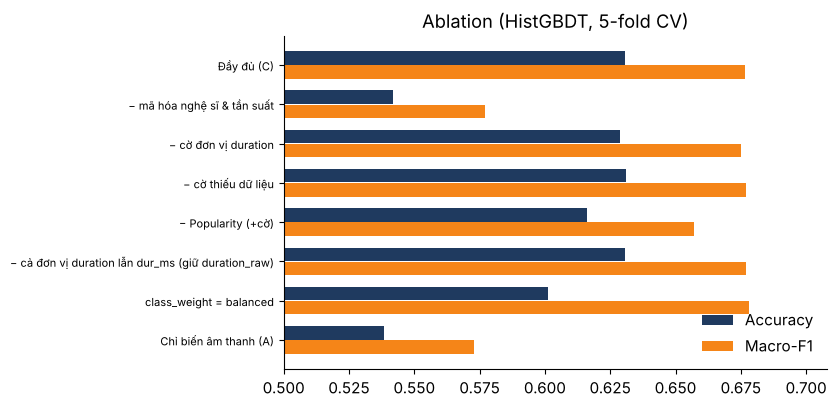

In [6]:
def cv_acc(Xf, fs, model, **kw):
    r = cross_validate(make_pipe(model, fs), Xf, y, cv=kf, scoring=('accuracy', 'f1_macro'), **kw); return r['test_accuracy'].mean(), r['test_f1_macro'].mean()
HG = lambda **k: HistGradientBoostingClassifier(max_iter=200, learning_rate=.08, random_state=SEED, **k)
te_cols = [c for c in XC.columns]
abl = []
def add(name, a, f): abl.append(dict(Config=name, Acc=a, F1=f))
add('Đầy đủ (C)', *cv_acc(XC, 'C', HG()))
add('− mã hóa nghệ sĩ & tần suất', *cv_acc(XB, 'B', HG()))
add('− cờ đơn vị duration', *cv_acc(XC.drop(columns=['dur_is_minutes']) if 'dur_is_minutes' in XC else XB.drop(columns=['dur_is_minutes']), 'C', HG()))
miss_cols = [c for c in XC.columns if c.endswith('_missing')]
add('− cờ thiếu dữ liệu', *cv_acc(XC.drop(columns=miss_cols), 'C', HG()))
add('− Popularity (+cờ)', *cv_acc(XC.drop(columns=['Popularity']), 'C', HG()))
add('− cả đơn vị duration lẫn dur_ms (giữ duration_raw)', *cv_acc(XC.drop(columns=['dur_is_minutes', 'dur_ms']), 'C', HG()))
add('class_weight = balanced', *cv_acc(XC, 'C', HG(class_weight='balanced')))
add('Chỉ biến âm thanh (A)', *cv_acc(XA, 'A', HG()))
ablt = pd.DataFrame(abl); ablt.to_csv('outputs/ablation_results.csv', index=False); print(ablt.round(4).to_string(index=False)); RES['ablation'] = ablt.round(4).to_dict('records')
fig, ax = plt.subplots(figsize=(8.5, 4.2)); yy = np.arange(len(ablt))[::-1]
ax.barh(yy + .18, ablt.Acc, .34, color=NAVY, label='Accuracy'); ax.barh(yy - .18, ablt.F1, .34, color=ORANGE, label='Macro-F1')
ax.set_yticks(yy); ax.set_yticklabels(ablt.Config, fontsize=8); ax.set_xlim(.5, ablt[['Acc', 'F1']].values.max() + .03); ax.legend(frameon=False, loc='lower right'); ax.set_title('Ablation (HistGBDT, 5-fold CV)')
plt.tight_layout(); plt.savefig('figs/fig6_ablation.png', dpi=200); plt.show()

## 6. Tinh chỉnh HistGBDT (RandomizedSearchCV, 5 fold dùng chung)

In [7]:
space = {'model__learning_rate': [.03, .05, .08, .1], 'model__max_iter': [150, 250, 400], 'model__max_leaf_nodes': [15, 31, 63],
         'model__l2_regularization': [0, 1, 5], 'model__min_samples_leaf': [20, 40, 80], 'model__max_depth': [None, 6, 10]}
rs = RandomizedSearchCV(make_pipe(HG(), 'C'), space, n_iter=10, cv=kf, scoring='accuracy', random_state=SEED, n_jobs=-1).fit(XC, y)
print('Tham số tốt nhất:', rs.best_params_, '| Accuracy CV: %.4f' % rs.best_score_)
RES['best_params'] = {k.replace('model__', ''): v for k, v in rs.best_params_.items()}; hgb_best = rs.best_estimator_

Tham số tốt nhất: {'model__min_samples_leaf': 80, 'model__max_leaf_nodes': 15, 'model__max_iter': 250, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__l2_regularization': 5} | Accuracy CV: 0.6355


## 7. Kết hợp mô hình (soft voting) bằng xác suất out-of-fold

In [8]:
cands = {'HistGBDT (tuned)': hgb_best, 'Random Forest': make_pipe(RandomForestClassifier(500, n_jobs=-1, random_state=SEED), 'C'),
         'Extra Trees': make_pipe(ExtraTreesClassifier(500, n_jobs=-1, random_state=SEED), 'C'), 'Logistic Regression': make_pipe(LogisticRegression(max_iter=2000), 'C'),
         'MLP': make_pipe(MLPClassifier((128, 64), max_iter=300, early_stopping=True, random_state=SEED), 'C')}
P = {n: cross_val_predict(m, XC, y, cv=kf, method='predict_proba', n_jobs=1) for n, m in cands.items()}
def score(p): pr = p.argmax(1); return accuracy_score(y, pr), f1_score(y, pr, average='macro')
combos = {'HistGBDT (tuned)': ['HistGBDT (tuned)'], 'HGB + ET': ['HistGBDT (tuned)', 'Extra Trees'], 'HGB + RF + ET': ['HistGBDT (tuned)', 'Random Forest', 'Extra Trees'],
          'HGB + RF + ET + LR': ['HistGBDT (tuned)', 'Random Forest', 'Extra Trees', 'Logistic Regression'], 'HGB + RF + ET + LR + MLP': list(cands)}
st = []
for n, ms in combos.items():
    p = np.mean([P[m] for m in ms], 0); a, f = score(p)
    fa = [accuracy_score(y[v], p[v].argmax(1)) for _, v in kf.split(XC, y)]
    st.append(dict(Config=n, Acc=a, Acc_Std=np.std(fa), F1=f))
stage = pd.DataFrame(st); stage.to_csv('outputs/final_stage_results.csv', index=False); print(stage.round(4).to_string(index=False)); RES['stage'] = stage.round(4).to_dict('records')
best_combo = stage.loc[stage.Acc.idxmax(), 'Config']; best_models = combos[best_combo]; pbest = np.mean([P[m] for m in best_models], 0); print('Chọn:', best_combo)
RES['best_combo'] = best_combo; RES['best_models'] = best_models
a, f = score(pbest); RES.update(final_acc=round(a, 4), final_f1=round(f, 4), final_acc_std=round(float(stage.loc[stage.Acc.idxmax(), 'Acc_Std']), 4))

                  Config    Acc  Acc_Std     F1
        HistGBDT (tuned) 0.6355   0.0027 0.6784
                HGB + ET 0.6384   0.0042 0.6810
           HGB + RF + ET 0.6355   0.0039 0.6781
      HGB + RF + ET + LR 0.6403   0.0045 0.6783
HGB + RF + ET + LR + MLP 0.6368   0.0033 0.6762
Chọn: HGB + RF + ET + LR


## 8. Phân tích lỗi

F1 theo lớp: {0: 0.828, 1: 0.032, 2: 0.676, 3: 0.854, 4: 0.832, 5: 0.796, 6: 0.483, 7: 0.958, 8: 0.705, 9: 0.661, 10: 0.636}
Cặp nhầm lẫn nhiều nhất (thực → dự đoán, tỉ lệ): [(1, 10, 0.43), (1, 6, 0.43), (6, 10, 0.32), (8, 10, 0.27), (2, 10, 0.21)]


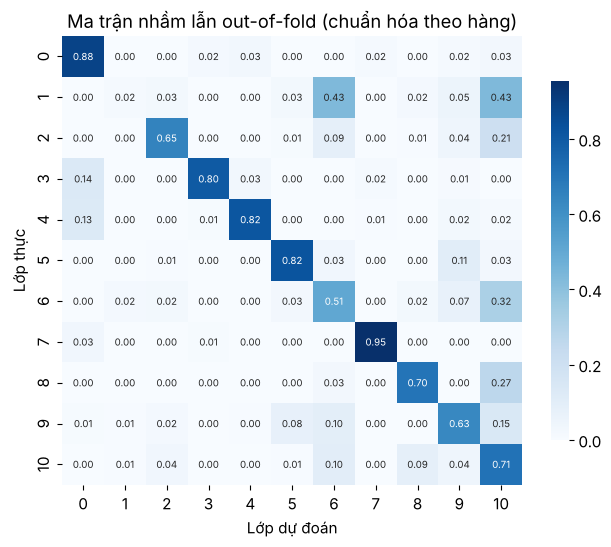

In [9]:
pr = pbest.argmax(1); cm = confusion_matrix(y, pr, normalize='true')
f1c = f1_score(y, pr, average=None); RES['f1_per_class'] = {int(k): round(float(v), 3) for k, v in enumerate(f1c)}; RES['recall_per_class'] = {int(k): round(float(v), 3) for k, v in enumerate(np.diag(cm))}
print('F1 theo lớp:', RES['f1_per_class'])
fig, ax = plt.subplots(figsize=(6.6, 5.6)); sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', annot_kws={'size': 7}, cbar_kws={'shrink': .8}, ax=ax)
ax.set_xlabel('Lớp dự đoán'); ax.set_ylabel('Lớp thực'); ax.set_title('Ma trận nhầm lẫn out-of-fold (chuẩn hóa theo hàng)')
plt.tight_layout(); plt.savefig('figs/fig8_confusion.png', dpi=200); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0); top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
RES['top_confusions'] = [(int(i), int(j), round(float(off[i, j]), 2)) for i, j in top]; print('Cặp nhầm lẫn nhiều nhất (thực → dự đoán, tỉ lệ):', RES['top_confusions'])

## 8b. Khi nghệ sĩ chưa từng xuất hiện trong train

In [10]:
seen = np.zeros(len(y), bool)
for tri, vai in kf.split(XC, y): seen[vai] = XC['artist'].iloc[vai].isin(set(XC['artist'].iloc[tri])).values
acc_seen, acc_unseen = accuracy_score(y[seen], pr[seen]), accuracy_score(y[~seen], pr[~seen])
print('Trong CV: %.1f%% mẫu validation có nghệ sĩ đã thấy | Accuracy: nghệ sĩ đã thấy %.4f, chưa thấy %.4f' % (seen.mean() * 100, acc_seen, acc_unseen))
from sklearn.model_selection import StratifiedGroupKFold
gkf = StratifiedGroupKFold(5, shuffle=True, random_state=SEED); grp = train['Artist Name'].values
g_res = {}
for nm, Xf, fs in (('B (không dùng nghệ sĩ)', XB, 'B'), ('C (có mã hóa nghệ sĩ)', XC, 'C')):
    r = cross_validate(make_pipe(HG(), fs), Xf, y, cv=gkf, groups=grp, scoring=('accuracy', 'f1_macro')); g_res[nm] = (r['test_accuracy'].mean(), r['test_f1_macro'].mean())
    print('GroupKFold theo nghệ sĩ –', nm, 'Acc %.4f | Macro-F1 %.4f' % g_res[nm])
RES.update(cv_seen_share=round(float(seen.mean()), 3), acc_seen=round(acc_seen, 4), acc_unseen=round(acc_unseen, 4), group_cv={k: [round(a, 4), round(b, 4)] for k, (a, b) in g_res.items()})

Trong CV: 58.7% mẫu validation có nghệ sĩ đã thấy | Accuracy: nghệ sĩ đã thấy 0.6747, chưa thấy 0.5915
GroupKFold theo nghệ sĩ – B (không dùng nghệ sĩ) Acc 0.5447 | Macro-F1 0.5745
GroupKFold theo nghệ sĩ – C (có mã hóa nghệ sĩ) Acc 0.5242 | Macro-F1 0.5548


## 9. Độ quan trọng đặc trưng (permutation theo nhóm, trên fold 1)

Accuracy gốc fold 1: 0.6337
artist_te (11 biến)                       0.2392
dur_is_minutes + dur_ms + duration_raw    0.1244
instrumentalness                          0.0343
acousticness                              0.0342
Popularity                                0.0271
energy                                    0.0262
speechiness                               0.0217
danceability                              0.0215
valence                                   0.0150
liveness                                  0.0042
dtype: float64


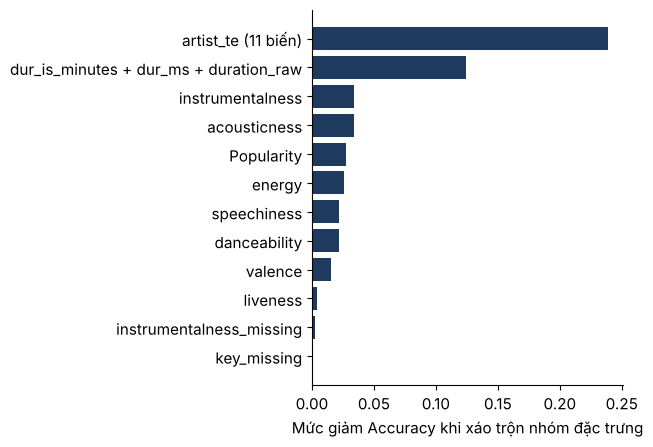

In [11]:
tri, vai = next(kf.split(XC, y)); pipe_f = clone(hgb_best).fit(XC.iloc[tri], y[tri])
Zte = pipe_f[:-1].transform(XC.iloc[vai]); mdl = pipe_f[-1]; cols = list(pipe_f[:-1].named_steps['te'].transform(XC.iloc[tri[:5]]).columns)
base = accuracy_score(y[vai], mdl.predict(Zte)); rng = np.random.RandomState(SEED)
groups = {c: [i] for i, c in enumerate(cols) if not c.startswith('artist_te_')}; groups['artist_te (11 biến)'] = [i for i, c in enumerate(cols) if c.startswith('artist_te_')]
groups['dur_is_minutes + dur_ms + duration_raw'] = [cols.index(c) for c in ('dur_is_minutes', 'dur_ms', 'duration_raw')]
for c in ('dur_is_minutes', 'dur_ms', 'duration_raw'): groups.pop(c, None)
imp = {}
for gname, ix in groups.items():
    drops = []
    for _ in range(5):
        Zp = Zte.copy(); perm = rng.permutation(len(Zp)); Zp[:, ix] = Zte[perm][:, ix]; drops.append(base - accuracy_score(y[vai], mdl.predict(Zp)))
    imp[gname] = float(np.mean(drops))
imp = pd.Series(imp).sort_values(ascending=False); print('Accuracy gốc fold 1: %.4f' % base); print(imp.round(4).head(10))
RES['perm_importance'] = imp.round(4).head(12).to_dict()
h = imp.head(12)[::-1]; fig, ax = plt.subplots(figsize=(6.6, 4.6)); ax.barh(h.index, h.values, color=NAVY); ax.set_xlabel('Mức giảm Accuracy khi xáo trộn nhóm đặc trưng')
plt.tight_layout(); plt.savefig('figs/fig7_importance.png', dpi=200); plt.show()

## 10. Huấn luyện mô hình cuối trên toàn bộ train và xuất `submission.csv`

In [12]:
XT = build(test, 'C'); probs = []
for m in best_models: probs.append(clone(cands[m]).fit(XC, y).predict_proba(XT))
pred = np.mean(probs, 0).argmax(1)
sub = pd.DataFrame({'Id': test.Id.values, 'Class': pred}); sub.to_csv('outputs/submission.csv', index=False)
assert len(sub) == len(sample) == 3600 and (sub.Id.values == sample.Id.values).all() and set(sub.Class) <= set(range(11)) and list(sub.columns) == list(sample.columns)
print('Đã xuất outputs/submission.csv:', sub.shape); print('Phân bố lớp dự đoán:', sub.Class.value_counts().sort_index().to_dict())
RES['pred_dist'] = {int(k): int(v) for k, v in sub.Class.value_counts().sort_index().items()}

Đã xuất outputs/submission.csv: (3600, 2)
Phân bố lớp dự đoán: {0: 143, 1: 23, 2: 244, 3: 76, 4: 78, 5: 291, 6: 588, 7: 108, 8: 353, 9: 466, 10: 1230}


## 11. Sơ đồ quy trình (Hình 1)

Đã lưu outputs/results_summary.json và 8 hình trong figs/


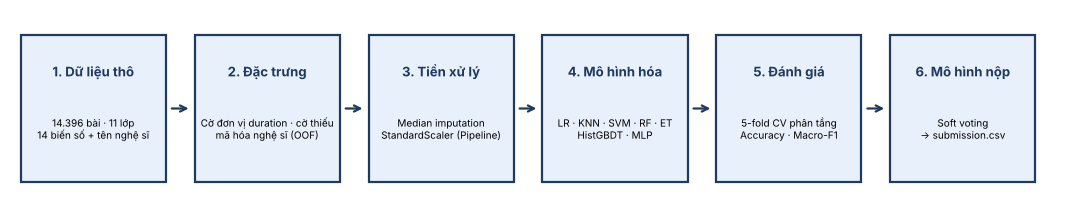

In [13]:
fig, ax = plt.subplots(figsize=(11, 2.3)); ax.axis('off'); ax.set_xlim(0, 100); ax.set_ylim(3, 27)
boxes = [('1. Dữ liệu thô', '14.396 bài · 11 lớp\n14 biến số + tên nghệ sĩ'), ('2. Đặc trưng', 'Cờ đơn vị duration · cờ thiếu\nmã hóa nghệ sĩ (OOF)'), ('3. Tiền xử lý', 'Median imputation\nStandardScaler (Pipeline)'),
         ('4. Mô hình hóa', 'LR · KNN · SVM · RF · ET\nHistGBDT · MLP'), ('5. Đánh giá', '5-fold CV phân tầng\nAccuracy · Macro-F1'), ('6. Mô hình nộp', 'Soft voting\n→ submission.csv')]
w, gap = 13.6, 2.7
for i, (t, s) in enumerate(boxes):
    x = i * (w + gap) + 1; ax.add_patch(plt.Rectangle((x, 6), w, 18, fc='#E8F0FB', ec=NAVY, lw=1.6))
    ax.text(x + w / 2, 19.5, t, ha='center', va='center', fontsize=9.5, fontweight='bold', color=NAVY); ax.text(x + w / 2, 12.5, s, ha='center', va='center', fontsize=7.2)
    if i < len(boxes) - 1: ax.annotate('', xy=(x + w + gap - .3, 15), xytext=(x + w + .3, 15), arrowprops=dict(arrowstyle='->', color=NAVY, lw=1.6))
plt.tight_layout(); plt.savefig('figs/fig1_pipeline.png', dpi=200, bbox_inches='tight', pad_inches=0.05); plt.show()
json.dump(RES, open('outputs/results_summary.json', 'w'), ensure_ascii=False, indent=1)
print('Đã lưu outputs/results_summary.json và', len(os.listdir('figs')), 'hình trong figs/')